In [2]:
import pandas as pd

# 1. 파일 전체 읽지 않고 메모리 아끼며 상위 1000줄만 먼저 확인
df_sample = pd.read_csv('dataset/kindle_reviews.csv', encoding='cp949')
print(df_sample.head())

   Unnamed: 0        asin helpful  overall  \
0           0  B000F83SZQ  [0, 0]        5   
1           1  B000F83SZQ  [2, 2]        4   
2           2  B000F83SZQ  [2, 2]        4   
3           3  B000F83SZQ  [1, 1]        5   
4           4  B000F83SZQ  [0, 1]        4   

                                          reviewText   reviewTime  \
0  I enjoy vintage books and movies so I enjoyed ...   05 5, 2014   
1  This book is a reissue of an old one; the auth...   01 6, 2014   
2  This was a fairly interesting read.  It had ol...   04 4, 2014   
3  I'd never read any of the Amy Brewster mysteri...  02 19, 2014   
4  If you like period pieces - clothing, lingo, y...  03 19, 2014   

       reviewerID                         reviewerName             summary  \
0  A1F6404F1VG29J                           Avidreader  Nice vintage story   
1   AN0N05A9LIJEQ                             critters        Different...   
2   A795DMNCJILA6                                  dot               Oldie

In [22]:
df_sample.info()
df_sample.shape
df_sample.head()

<class 'pandas.DataFrame'>
RangeIndex: 982619 entries, 0 to 982618
Data columns (total 10 columns):
 #   Column          Non-Null Count   Dtype
---  ------          --------------   -----
 0   Unnamed: 0      982619 non-null  int64
 1   asin            982619 non-null  str  
 2   helpful         982619 non-null  str  
 3   overall         982619 non-null  int64
 4   reviewText      982597 non-null  str  
 5   reviewTime      982619 non-null  str  
 6   reviewerID      982619 non-null  str  
 7   reviewerName    978797 non-null  str  
 8   summary         982500 non-null  str  
 9   unixReviewTime  982619 non-null  int64
dtypes: int64(3), str(7)
memory usage: 75.0 MB


,Unnamed: 0,asin,helpful,overall,reviewText,reviewTime,reviewerID,reviewerName,summary,unixReviewTime
0,0,B000F83SZQ,"[0, 0]",5,I enjoy vintage books and movies so I enjoyed ...,"05 5, 2014",A1F6404F1VG29J,Avidreader,Nice vintage story,1399248000
1,1,B000F83SZQ,"[2, 2]",4,This book is a reissue of an old one; the auth...,"01 6, 2014",AN0N05A9LIJEQ,critters,Different...,1388966400
2,2,B000F83SZQ,"[2, 2]",4,This was a fairly interesting read. It had ol...,"04 4, 2014",A795DMNCJILA6,dot,Oldie,1396569600
3,3,B000F83SZQ,"[1, 1]",5,I'd never read any of the Amy Brewster mysteri...,"02 19, 2014",A1FV0SX13TWVXQ,"Elaine H. Turley ""Montana Songbird""",I really liked it.,1392768000
4,4,B000F83SZQ,"[0, 1]",4,"If you like period pieces - clothing, lingo, y...","03 19, 2014",A3SPTOKDG7WBLN,Father Dowling Fan,Period Mystery,1395187200


['sans-serif']


C:\Users\human-08\AppData\Local\Temp\ipykernel_14964\3045537564.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_sample2, x='overall', palette='viridis')


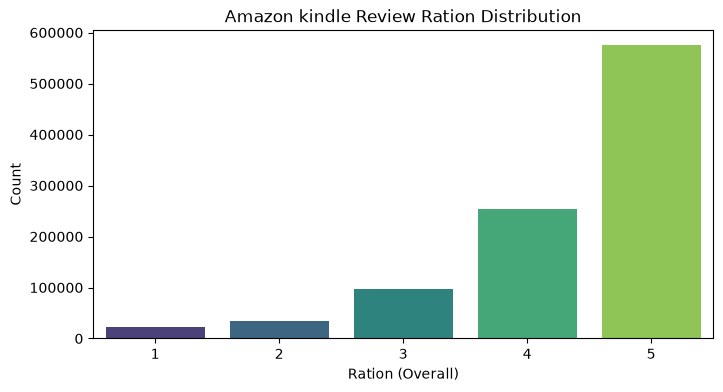

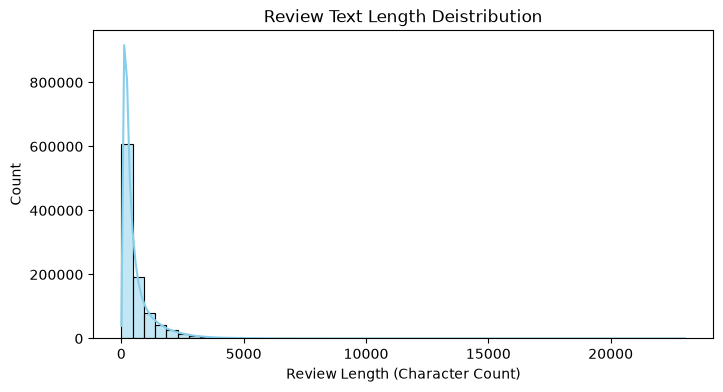

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

# 결측치 (null) 먼저 제거
df_sample2 = df_sample.dropna(subset=['reviewText'])


# 한글 폰트 깨짐 방지 
plt.rcParams['font.family'] = 'sans-serif' # 전역 설정 딕셔너리??? 
print(plt.rcParams['font.family'])

# 1. 별점(overall) 분포 확인 (막대 그래프)
plt.figure(figsize=(8,4))
sns.countplot(data=df_sample2, x='overall', palette='viridis')
plt.title('Amazon kindle Review Ration Distribution')
plt.xlabel('Ration (Overall)')
plt.ylabel('Count')
plt.show()

# 2. 리뷰 글자 수(Length) 분포 확인 (히스토그램)
# 리뷰 텍스트 컬럼명이 'reviewText"라고 가정
df_sample2['review_length'] = df_sample2['reviewText'].astype(str).apply(len)

plt.figure(figsize=(8,4))
sns.histplot(df_sample2['review_length'], bins=50, color='skyblue', kde=True)
plt.title("Review Text Length Deistribution")
plt.xlabel('Review Length (Character Count)')
plt.ylabel('Count')
plt.show()



In [ ]:
## 확인을 해보니 심각한 클래스 불균형이 있다.....
## 다운 샘플링 적용을 결정...


In [4]:
# 데이터 전처리... EDA와 피처 엔지니어링

# 결측치가 있는 행 삭제
df = df_sample.dropna(subset=['reviewText'])

# summary 컬럼의 결측치는 빈 문자열('')로 채우기
df['summary']=df['summary'].fillna('')

print("결측치 정리 후 shape:", df.shape)
df.info()

결측치 정리 후 shape: (982597, 10)
<class 'pandas.DataFrame'>
Index: 982597 entries, 0 to 982618
Data columns (total 10 columns):
 #   Column          Non-Null Count   Dtype
---  ------          --------------   -----
 0   Unnamed: 0      982597 non-null  int64
 1   asin            982597 non-null  str  
 2   helpful         982597 non-null  str  
 3   overall         982597 non-null  int64
 4   reviewText      982597 non-null  str  
 5   reviewTime      982597 non-null  str  
 6   reviewerID      982597 non-null  str  
 7   reviewerName    978775 non-null  str  
 8   summary         982597 non-null  str  
 9   unixReviewTime  982597 non-null  int64
dtypes: int64(3), str(7)
memory usage: 82.5 MB


In [5]:
# reviewerName, reviewerID은 그냥 버리기
df.drop(columns=['reviewerID', 'reviewerName'])

,Unnamed: 0,asin,helpful,overall,reviewText,reviewTime,summary,unixReviewTime
0,0,B000F83SZQ,"[0, 0]",5,I enjoy vintage books and movies so I enjoyed ...,"05 5, 2014",Nice vintage story,1399248000
1,1,B000F83SZQ,"[2, 2]",4,This book is a reissue of an old one; the auth...,"01 6, 2014",Different...,1388966400
2,2,B000F83SZQ,"[2, 2]",4,This was a fairly interesting read. It had ol...,"04 4, 2014",Oldie,1396569600
3,3,B000F83SZQ,"[1, 1]",5,I'd never read any of the Amy Brewster mysteri...,"02 19, 2014",I really liked it.,1392768000
4,4,B000F83SZQ,"[0, 1]",4,"If you like period pieces - clothing, lingo, y...","03 19, 2014",Period Mystery,1395187200
...,...,...,...,...,...,...,...,...
982614,982614,B00M13FNSS,"[2, 2]",5,Yasss hunny! This is a great read. That Dre is...,"07 23, 2014",A Hot Read Indeed!!,1406073600
982615,982615,B00M13FNSS,"[0, 0]",5,I ENJOYED THIS BOOK FROM BEGINNING TO END NOW ...,"07 23, 2014",VERY GOOD BOOK,1406073600
982616,982616,B00M13FNSS,"[1, 1]",5,Great book! Cherika was a fool. She let that m...,"07 23, 2014",Great Read,1406073600
982617,982617,B00M13FNSS,"[0, 0]",5,When I say this was an excellent book please b...,"07 23, 2014",Wow!!,1406073600


In [6]:
# 1. 별점 3점인 데이터는 제외 (노이즈 제거를 위해)
df = df[df['overall'] != 3] # 조건부 필터링. 불리언 인덱싱 방식 조건이 참인 행들만 모아서 데이터 프레임을 재조립 해준다.

# 2. 4~5점 은 1(긍정), 1~2점은 0(부정)으로 새로운 라벨 생성 (라벨링)
def make_label(score):
    if score >= 4: # 점수가 4이상이면 1 리턴 아니면 0 리턴
        return 1 # 긍정
    else:
        return 0 # 부정
    
df['sentiment'] = df['overall'].apply(make_label) # sentiment라는 컬럼을 만들고 거기에 overall컬럼의 1,2,4,5 형식의 데이터들을 make_label이라는 함수를 거처서 반환된 값을 넣어라. -> 약 98만개의 값이 들어가게됨

# 라벨이 잘 나뉘었는지 개수 확인
print(df['sentiment'].value_counts()) # value_count()매서드. sentiment라는 컬럼의 어떤 값들이 몇개 들어있는지 console에 보여주어라.

sentiment
1    829256
0     57148
Name: count, dtype: int64


In [7]:
df.drop(columns='reviewerName', inplace=True)

In [8]:
df.info()
## 결측치는 완전히 제거하였다.

<class 'pandas.DataFrame'>
Index: 886404 entries, 0 to 982618
Data columns (total 10 columns):
 #   Column          Non-Null Count   Dtype
---  ------          --------------   -----
 0   Unnamed: 0      886404 non-null  int64
 1   asin            886404 non-null  str  
 2   helpful         886404 non-null  str  
 3   overall         886404 non-null  int64
 4   reviewText      886404 non-null  str  
 5   reviewTime      886404 non-null  str  
 6   reviewerID      886404 non-null  str  
 7   summary         886404 non-null  str  
 8   unixReviewTime  886404 non-null  int64
 9   sentiment       886404 non-null  int64
dtypes: int64(4), str(6)
memory usage: 74.4 MB


In [9]:
import re # 정규 표현식 라이브러리

def clean_text(text):
    # 문자열이 아닌 경우(혹시 모를 예외 처리) 빈 문자열 반환
    if not isinstance(text, str):
        return ''
    
    # 1. 소문자 변솬
    text = text.lower() # lower-> 문자열을 소문자로 변환해주는 매서드
    
    # 2. HTML 태그 제거 (예: <br>, <p> 등)
    text = re.sub(r'<.*?>', '', text) # sub매서드는 특정 문자열에서 패턴을 찾아 다른 문자열로 치환하는 매서드 substitute(대체하다) . < <-이 기호로 시작해서 > <- 이 기호로 끝나는 모양을 아무것도 없는 빈 문자열로 바꿔치기 해라!
    
    # 3. 알파벳과 숫자를 제외한 특수문자/ 이모지 등을 공백으로 치환
    text = re.sub(r'[^a-zA-Z0-9\s]', '', text)
    
    # 4. 연속되는 공백 하나로 줄이기
    text = re.sub(r'\s+', ' ', text).strip()
    
    return text

# 리뷰 텍스트 정제 적용 
print("텍스트 정제 시작...")
df['clean_review'] = df['reviewText'].apply(clean_text) # df라는 이름의 데이터프레임에 clean_review라는 컬럼을 만들고 clean_text라는 함수를 거쳐서 그 반환값들을 clean_review라는 컬럼에 넣어라...
print("텍스트 정제 완료")

# 결과 확인
display(df[['reviewText', 'clean_review', 'sentiment']].head())

텍스트 정제 시작...
텍스트 정제 완료


,reviewText,clean_review,sentiment
0,I enjoy vintage books and movies so I enjoyed ...,i enjoy vintage books and movies so i enjoyed ...,1
1,This book is a reissue of an old one; the auth...,this book is a reissue of an old one the autho...,1
2,This was a fairly interesting read. It had ol...,this was a fairly interesting read it had old ...,1
3,I'd never read any of the Amy Brewster mysteri...,id never read any of the amy brewster mysterie...,1
4,"If you like period pieces - clothing, lingo, y...",if you like period pieces clothing lingo you w...,1


In [10]:
# 다운 샘플링 

# 1. 부정(0) 데이터와 긍정(1) 데이터 분리
df_negative = df[df['sentiment'] == 0]
df_positive = df[df['sentiment'] == 1]

print(f'다운 샘플링 전 -> 부정 리뷰: {len(df_negative):,}개 | 긍정 리뷰: {len(df_positive):,}개')

# 2. 부정 데이터 개수에 맞춰 긍정 데이터를 1:1 비율로 랜덤 추출 (다운 샘플링)
df_positive_downsampled = df_positive.sample(n=len(df_negative), random_state=42)

# 3. 두 데이터셋을 합쳐서 완벽한 1:1 균형 데이터셋 완성
df_balanced = pd.concat([df_negative, df_positive_downsampled])

# 4. 모델이 한쪽으로 치우쳐서 학습하지 않도록 데이터 순서 섞기
df_balanced = df_balanced.sample(frac=1, random_state=42).reset_index(drop=True)

print('\n--- [최종 다운 샘플링 결과] ---')
print(df_balanced['sentiment'].value_counts())
print(f"최종 학습용 총 데이터 개수: {len(df_balanced):,}개")

다운 샘플링 전 -> 부정 리뷰: 57,148개 | 긍정 리뷰: 829,256개

--- [최종 다운 샘플링 결과] ---
sentiment
1    57148
0    57148
Name: count, dtype: int64
최종 학습용 총 데이터 개수: 114,296개


In [40]:
df_balanced.head()

,Unnamed: 0,asin,helpful,overall,reviewText,reviewTime,reviewerID,summary,unixReviewTime,sentiment,clean_review
0,907388,B00JVURTYU,"[0, 0]",5,Stranded is the second book in the Hijacked se...,"06 5, 2014",A2Z3DQ7P9JYRLG,Stranded review,1401926400,1,stranded is the second book in the hijacked se...
1,77896,B0054H1I7S,"[0, 0]",1,I'm not into Werewolves; was a little mislead ...,"10 26, 2013",AIYC32G25QQPU,Sci-fi,1382745600,0,im not into werewolves was a little mislead by...
2,222650,B0080S2BJC,"[2, 2]",2,"I normally finish what I start, including book...","07 10, 2012",A1VV2GMSS89VFE,Save your money unless you're really bored,1341878400,0,i normally finish what i start including books...
3,135392,B0067QUH6I,"[1, 2]",2,I am not sure why I kept reading this but I fi...,"02 24, 2013",A1W33JCFXE58K0,2.5 stars,1361664000,0,i am not sure why i kept reading this but i fi...
4,309067,B009F3M9ZC,"[1, 2]",2,It was okay. I mean I guess for free what did ...,"12 29, 2012",A1B7514ASZYFZ9,Eh,1356739200,0,it was okay i mean i guess for free what did y...


In [39]:
df_balanced.shape

(114296, 11)

In [11]:
from sklearn.feature_extraction.text import TfidfVectorizer

print('TF-IDF 벡터화 진행 중...')

# 1. TfidVectorizer 객체 생성
# max_features=10000: 메모리 폭발을 막기 위해 전체 데이터에서 가장 중요한 단어 상위 10,000개만 사용
# stop_words = 'english': the, a , is 같은 의미 없는 영문 불용어 걸러주는 매개변수
vectorizer = TfidfVectorizer(max_features = 1000)

# 2. 정제된 리뷰 텍스트(clean_review)를 숫자 행렬(X)로 변환
X = vectorizer.fit_transform(df_balanced['reviewText'])

# 3. 정답 데이터 (sentiment)를 y로 분리
y= df_balanced['sentiment']

print('벡터화 완료!')
print('변환된 독립 변수 (X) 크기:', X.shape)
print('정답 데이터(y) 크기:', y.shape)

TF-IDF 벡터화 진행 중...
벡터화 완료!
변환된 독립 변수 (X) 크기: (114296, 1000)
정답 데이터(y) 크기: (114296,)


In [16]:
df_balanced.head()
print(X.shape)
print(y.shape)

(114296, 1000)
(114296,)


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# 1. 훈련용(Train)과 데스트용(Test) 데이터 분리 (예: 80% 학습, 20% 테스트)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f'학습용 데이터 크기 (X_train):{X_train.shape}')
print(f'테스트용 데이터 크기 (X_test):{X_test.shape}')

# 2. 로지스틱 회귀(Logistic Regression) 모델 객체 생성 및 학습
print('\n모델 학습 중...')
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train, y_train)
print('모델 학습 완료')

# 3. 테스트 데이터로 예측 수행
y_pred = model.predict(X_test)

# 4. 성능 평가 (정확도 및 상세 리포트)
accuracy = accuracy_score(y_test, y_pred)
print(f'\n---- [모델 성능 평가] ----')
print(f'정확도(Accuracy): {accuracy}')
print('\n[상세 분류 리포트]')
print(classification_report(y_test, y_pred))

학습용 데이터 크기 (X_train):(91436, 1000)
테스트용 데이터 크기 (X_test):(22860, 1000)

모델 학습 중...
모델 학습 완료

---- [모델 성능 평가] ----
정확도(Accuracy): 0.91

[상세 분류 리포트]
              precision    recall  f1-score   support

           0       0.91      0.92      0.91     11435
           1       0.92      0.91      0.91     11425

    accuracy                           0.91     22860
   macro avg       0.91      0.91      0.91     22860
weighted avg       0.91      0.91      0.91     22860



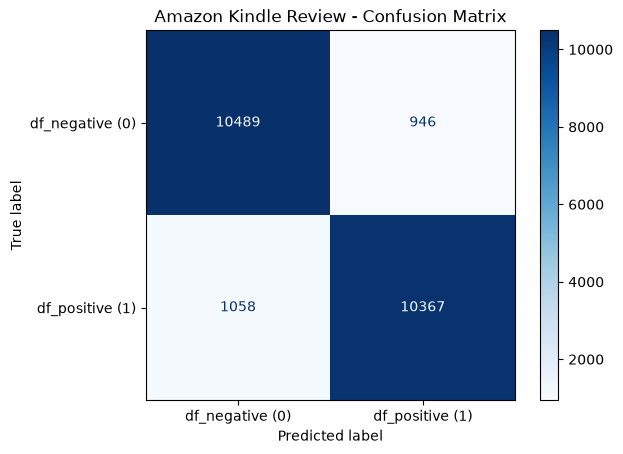

In [19]:
# 모델 예측 결과 시각화
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# 혼동 행렬 계산
cm = confusion_matrix(y_test, y_pred)

# 시각화 객체 생성
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['df_negative (0)', 'df_positive (1)'])

disp.plot(cmap=plt.cm.Blues, values_format='d')
plt.title('Amazon Kindle Review - Confusion Matrix')
plt.show()


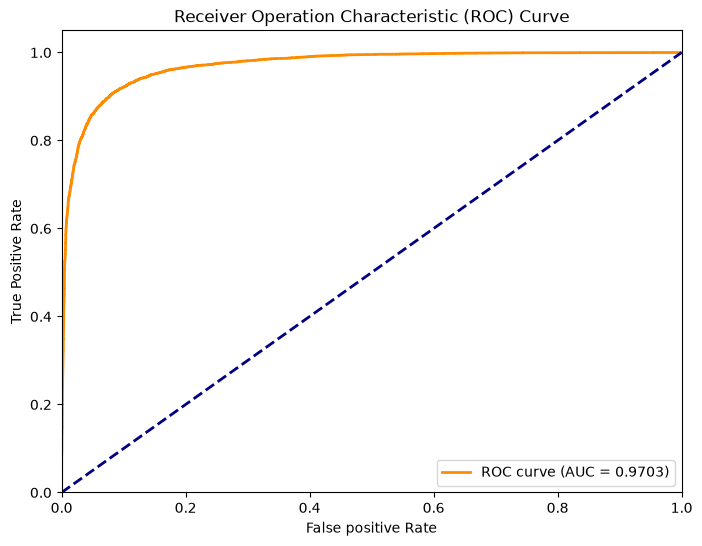

In [20]:
from sklearn.metrics import roc_curve, auc

# 확률값 가져오기 (1로 예측될 확률)
y_prob = model.predict_proba(X_test)[:, 1]

# FPR, TPR 계산
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

# 시각화
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.4f})')
plt.plot([0,1], [0,1], color = 'navy', lw=2, linestyle = '--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operation Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.show()

In [24]:
# 1. TF-IDF 벡터라이저에서 단어 이름들 가져오기
feature_names = vectorizer.get_feature_names_out()

# 2. 로지스틱 회귀 모델의 계수(Coefficient) 가져오기
# (이진 분류의 경우 model.coef_[0]에 각 단어별 가중치가 들어 있다.)

feature_importances = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': model.coef_[0]
})

# 절대값이 큰 순서 (영향력이 큰 순서)대로 정렬
feature_importances['Abs_Coefficient'] = feature_importances['Coefficient'].abs()
feature_importances = feature_importances.sort_values(by='Abs_Coefficient', ascending=False)

print("\n상위 중요 단어 (Feature Importances):")
print(feature_importances.head(20))


상위 중요 단어 (Feature Importances):
           Feature  Coefficient  Abs_Coefficient
510          loved     9.362405         9.362405
587            not    -9.139363         9.139363
925           wait     8.851587         8.851587
243        enjoyed     8.585057         8.585057
934          waste    -8.153892         8.153892
354          great     7.788483         7.788483
101         boring    -7.552899         7.552899
907  unfortunately    -6.750545         6.750545
391         highly     6.655149         6.655149
969      wonderful     6.365518         6.365518
658      potential    -6.281235         6.281235
262      excellent     6.269098         6.269098
655         poorly    -5.985143         5.985143
208  disappointing    -5.950240         5.950240
40         amazing     5.886286         5.886286
582             no    -5.843769         5.843769
589        nothing    -5.836900         5.836900
786          sorry    -5.818840         5.818840
329            fun     5.751968     

In [25]:
import os
import joblib

# 'model' 폴더 생성
os.makedirs('model', exist_ok=True)

# 1. 학습된 로지스틱 회귀 모델 저장
joblib.dump(model, 'model/sentiment_model.joblib')

# 2. 텍스트를 숫자로 바구는 TF-IDF 벡터라이저 저장 (베포할 때 필수)
joblib.dump(vectorizer, 'model/tfidf_vectorizer.joblib')

print("모든 모델 및 전처리 파일 model/ 폴더에 저장 완료")

모든 모델 및 전처리 파일 model/ 폴더에 저장 완료
